<a href="https://colab.research.google.com/github/roaaats-maker/Breast-Cancer-ML/blob/main/breast_cancer_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Stage 1: Data Cleaning, Preparation & EDA

## 1.1 Loading the Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("https://raw.githubusercontent.com/roaaats-maker/Breast-Cancer-ML/main/data.csv")
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


## 1.2 Understanding the Data

In [ ]:
print(df.shape)
df.info()

In [ ]:
df.describe().T

In [ ]:
df['diagnosis'].value_counts()

The dataset has 569 rows and 33 columns. The target variable is diagnosis (M = malignant, B = benign). All 30 features are numeric measurements of cell nuclei, in addition to an id column. There is a column called Unnamed: 32 that contains only missing values.

## 1.3 Data Cleaning

In [ ]:
df.isnull().sum().sort_values(ascending=False).head()

In [ ]:
df = df.drop(columns=['id', 'Unnamed: 32'])
df.shape

In [ ]:
df.duplicated().sum()

In [ ]:
df['diagnosis'] = df['diagnosis'].map({'M': 1, 'B': 0})
df['diagnosis'].value_counts()

The column Unnamed: 32 contained only missing values, so it was removed. The id column is only an identifier and has no predictive value, so it was also dropped. No duplicate rows were found. The target diagnosis was encoded as M = 1 (malignant) and B = 0 (benign), giving 212 malignant and 357 benign cases.

## 1.4 Outliers


In [ ]:
features = df.drop(columns='diagnosis').columns
Q1 = df[features].quantile(0.25)
Q3 = df[features].quantile(0.75)
IQR = Q3 - Q1
outliers = ((df[features] < Q1 - 1.5*IQR) | (df[features] > Q3 + 1.5*IQR)).sum()
outliers.sort_values(ascending=False).head(10)

In [ ]:
sns.boxplot(x='diagnosis', y='area_mean', data=df)
plt.show()

The IQR method showed outliers in many features, with area_se having the most (65 values). However, these outliers were not removed, because the dataset is small (569 rows) and the extreme values mostly belong to malignant tumors, so they carry useful information rather than being errors. The boxplot of area_mean confirms this: malignant tumors have a higher median (about 930 vs. 450) and the most extreme values (above 2000). Instead of removing them, feature scaling will be applied later to reduce their effect.

## 1.5 Exploratory Data Analysis (EDA)

In [ ]:
sns.countplot(x='diagnosis', data=df)
plt.show()
print(df['diagnosis'].value_counts(normalize=True))

The target variable is slightly imbalanced: 62.7% of the cases are benign (357) and 37.3% are malignant (212). The imbalance is mild, so no resampling is needed, but accuracy alone may be misleading. Therefore, recall, precision and F1-score will also be used when evaluating the models, since missing a malignant case is more costly than a false alarm.

In [ ]:
for col in ['radius_mean', 'texture_mean', 'concavity_mean', 'area_mean']:
    sns.histplot(data=df, x=col, hue='diagnosis', kde=True)
    plt.show()

The histograms show that malignant tumors tend to have higher values than benign ones in radius_mean, area_mean and concavity_mean. For example, benign tumors are concentrated around a radius of 12 and an area of 500, while malignant tumors are centered around a radius of 18-20 and have a wider range of areas. Concavity is close to zero for most benign cases but higher for malignant ones. In contrast, texture_mean shows a large overlap between the two classes, so it is a weaker feature for separating them. Most distributions are right-skewed.


In [ ]:
plt.figure(figsize=(18, 14))
sns.heatmap(df.corr(), cmap='coolwarm', center=0)
plt.show()

In [ ]:
df.corr()['diagnosis'].drop('diagnosis').sort_values(ascending=False)

The correlation heatmap shows that radius, perimeter and area (in their mean and worst versions) are almost perfectly correlated with each other, which means they carry nearly the same information (multicollinearity). The features most correlated with the diagnosis are concave points_worst (0.79), perimeter_worst (0.78), concave points_mean (0.78) and radius_worst (0.78), while fractal_dimension_mean, texture_se, symmetry_se and smoothness_se have almost no correlation with it (close to 0). This suggests that some features are redundant and others are not useful, so feature selection is needed.

## 1.6 Feature Selection

In [ ]:
corr = df.drop(columns='diagnosis').corr().abs()
target_corr = df.corr()['diagnosis'].abs()
cols = corr.columns

to_drop = set()
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        if corr.iloc[i, j] > 0.9:
            a, b = cols[i], cols[j]
            to_drop.add(a if target_corr[a] < target_corr[b] else b)

print(len(to_drop))
print(sorted(to_drop))

In [ ]:
df_selected = df.drop(columns=list(to_drop))
print(df_selected.shape)
print(list(df_selected.columns))

To reduce multicollinearity, we looked for pairs of features with a correlation higher than 0.9. In each pair, the feature with the weaker correlation with the diagnosis was removed and the stronger one was kept. This removed 10 features (such as radius_mean, area_mean, perimeter_mean and concave points_mean), while stronger representatives such as perimeter_worst and concave points_worst were kept. The result is a reduced dataset of 20 features, which lowers redundancy and should make the models simpler and more stable.

### Feature importance check (Random Forest)


In [ ]:
from sklearn.ensemble import RandomForestClassifier

X = df_selected.drop(columns='diagnosis')
y = df_selected['diagnosis']

rf = RandomForestClassifier(random_state=42)
rf.fit(X, y)

importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importances)

importances.sort_values().plot(kind='barh', figsize=(8, 7))
plt.title('Feature importance (Random Forest)')
plt.show()


A Random Forest was used to check the importance of the remaining 20 features. The most important ones are perimeter_worst (0.25), concave points_worst (0.25) and concavity_worst (0.12), which agrees with the correlation analysis. Features such as texture_se, symmetry_mean and symmetry_se have very low importance (about 0.01). Since the dataset is small and the correlated features were already removed, we kept all 20 features as the final set, so that the models can decide which ones are useful. This check was done only for exploration and the real model training is done after splitting the data.

In [ ]:
df_selected.to_csv("data_clean.csv", index=False)

#Stage 2: Data Splitting

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import warnings
from sklearn.model_selection import train_test_split
warnings.filterwarnings('ignore', category=FutureWarning)

RANDOM_STATE = 42

df = pd.read_csv('https://raw.githubusercontent.com/roaaats-maker/Breast-Cancer-ML/main/data_clean.csv')
X = df.drop(columns='diagnosis')
y = df['diagnosis']
print(X.shape, y.value_counts().to_dict())

(569, 20) {0: 357, 1: 212}


We load the cleaned dataset from Stage 1 (data_clean.csv): 569 samples, 20 features and the target (357 benign, 212 malignant).

In [ ]:
# Step 1: hold out 15% as the test set
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=RANDOM_STATE)

# Step 2: split the remaining 85% into train (70% of total) and validation (15% of total)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.15/0.85, stratify=y_temp, random_state=RANDOM_STATE)

split_summary = pd.DataFrame({
    'Set': ['Train', 'Validation', 'Test'],
    'Samples': [len(y_train), len(y_val), len(y_test)],
    'Malignant (%)': [round(100*s.mean(), 1) for s in (y_train, y_val, y_test)],
})
split_summary

,Set,Samples,Malignant (%)
0,Train,397,37.3
1,Validation,86,37.2
2,Test,86,37.2


The data was split into 70% training, 15% validation and 15% test, using stratify so that every set keeps the same class ratio (about 37% malignant). We chose this ratio because the dataset is small (569 rows), so we keep most of the data for training, while 86 samples (32 malignant) in each of the validation and test sets is still enough for a reliable evaluation. A smaller split such as 80/10/10 would leave only about 21 malignant cases per set, so one wrong prediction would change recall by about 5%. Hyperparameters are tuned with cross-validation on the training set, so the validation set is only used to check overfitting, and the test set is kept for the final evaluation.

In [ ]:
from sklearn.preprocessing import StandardScaler

# fit the scaler on the training set ONLY (no data leakage)
scaler = StandardScaler().fit(X_train)
X_train_s = pd.DataFrame(scaler.transform(X_train), columns=X.columns, index=X_train.index)
X_val_s   = pd.DataFrame(scaler.transform(X_val),   columns=X.columns, index=X_val.index)
X_test_s  = pd.DataFrame(scaler.transform(X_test),  columns=X.columns, index=X_test.index)

# save the splits so the whole team uses the same data
for name, Xs, ys in [('train', X_train, y_train), ('val', X_val, y_val), ('test', X_test, y_test)]:
    Xs.assign(diagnosis=ys).to_csv(f'{name}.csv', index=False)
joblib.dump(scaler, 'scaler.joblib')
print('Saved train.csv, val.csv, test.csv and scaler.joblib')

Saved train.csv, val.csv, test.csv and scaler.joblib


The StandardScaler was fitted on the training set only and then applied to the validation and test sets, to avoid data leakage. The three sets were saved as train.csv, val.csv and test.csv so that all models, including the Neural Network, use exactly the same data.

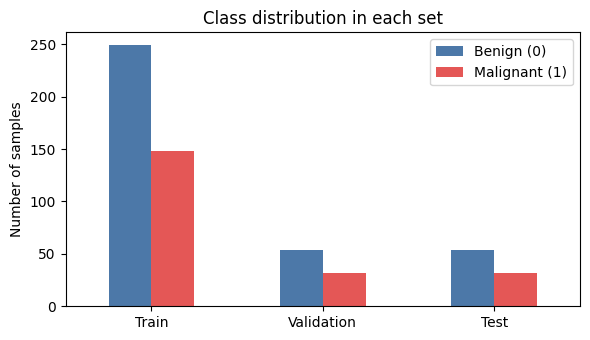

In [ ]:
counts = pd.DataFrame({
    'Benign (0)':    [int((s == 0).sum()) for s in (y_train, y_val, y_test)],
    'Malignant (1)': [int((s == 1).sum()) for s in (y_train, y_val, y_test)],
}, index=['Train', 'Validation', 'Test'])

ax = counts.plot(kind='bar', figsize=(6, 3.5), color=['#4C78A8', '#E45756'], rot=0)
ax.set_ylabel('Number of samples')
ax.set_title('Class distribution in each set')
plt.tight_layout()
plt.savefig('fig_split.png', dpi=150)
plt.show()

The plot confirms that the class distribution is the same in the three sets, so the evaluation will not be biased by the split.

#Stage 3: Model Selection and Development

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

def scores(model, X_, y_):
    p = model.predict(X_); pr = model.predict_proba(X_)[:, 1]
    return {'Accuracy': accuracy_score(y_, p), 'Precision': precision_score(y_, p),
            'Recall': recall_score(y_, p), 'F1': f1_score(y_, p), 'ROC-AUC': roc_auc_score(y_, pr)}

lr_base = Pipeline([('scaler', StandardScaler()),
                    ('clf', LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))])
rf_base = RandomForestClassifier(random_state=RANDOM_STATE)

rows = []
for name, m in [('Logistic Regression', lr_base), ('Random Forest', rf_base)]:
    m.fit(X_train, y_train)
    for set_name, Xs, ys in [('Train', X_train, y_train), ('Validation', X_val, y_val)]:
        rows.append({'Model': name, 'Set': set_name, **scores(m, Xs, ys)})
baseline = pd.DataFrame(rows).round(3)
baseline

,Model,Set,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,Train,0.982,0.993,0.959,0.976,0.997
1,Logistic Regression,Validation,0.977,1.000,0.938,0.968,0.998
2,Random Forest,Train,1.000,1.000,1.000,1.000,1.000
3,Random Forest,Validation,0.953,0.967,0.906,0.935,0.995


We chose Logistic Regression as a simple, interpretable linear model, because the EDA showed that a few features are strongly and almost linearly related to the diagnosis, and correlated features were already removed. We chose Random Forest because it captures non-linear relationships, is robust to the outliers we kept and does not need scaling. With default settings, Random Forest scores 1.000 on the training set but only 0.935 F1 on validation, which shows overfitting. Logistic Regression has similar training and validation scores, but misses 2 of the 32 malignant validation cases (recall 0.938).

#Stage 4: Training and Hyperparameter Optimization

In [ ]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

lr_grid = {
    'clf__C': [0.001, 0.01, 0.1, 1, 10, 100],
    'clf__penalty': ['l1', 'l2'],
    'clf__class_weight': [None, 'balanced'],
}
lr_search = GridSearchCV(
    Pipeline([('scaler', StandardScaler()),
              ('clf', LogisticRegression(solver='liblinear', max_iter=5000, random_state=RANDOM_STATE))]),
    lr_grid, cv=cv, scoring='f1', return_train_score=True, n_jobs=-1)
lr_search.fit(X_train, y_train)
print('Best LR params:', lr_search.best_params_)
print('Best CV F1: %.3f' % lr_search.best_score_)

Best LR params: {'clf__C': 1, 'clf__class_weight': 'balanced', 'clf__penalty': 'l2'}
Best CV F1: 0.965


Hyperparameters were tuned with GridSearchCV and 5-fold stratified cross-validation on the training set, using F1 as the scoring metric because it balances recall and precision. The best settings are C = 1 (moderate regularization), L2 penalty and class_weight = balanced, which gives more weight to malignant cases to improve recall. The best cross-validation F1 is 0.965.

In [ ]:
rf_grid = {
    'n_estimators': [100, 300, 500],
    'max_depth': [None, 4, 6, 8],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2'],
    'class_weight': [None, 'balanced'],
}
rf_search = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE),
                         rf_grid, cv=cv, scoring='f1', return_train_score=True, n_jobs=-1)
rf_search.fit(X_train, y_train)
print('Best RF params:', rf_search.best_params_)
print('Best CV F1: %.3f' % rf_search.best_score_)

Best RF params: {'class_weight': 'balanced', 'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 100}
Best CV F1: 0.939


The best Random Forest settings are max_depth = 8, class_weight = balanced, max_features = sqrt, min_samples_leaf = 1 and n_estimators = 100, with a cross-validation F1 of 0.939. However, max_depth = 8 still allows the trees to fit the training data almost perfectly, which we check in the next steps. class_weight = balanced gives more weight to malignant cases to improve recall, and 100 trees were enough, as more trees did not improve the score. Random Forest's CV F1 is lower than Logistic Regression's (0.965).

In [ ]:
def cv_row(name, search):
    r = search.cv_results_; i = search.best_index_
    return {'Model': name,
            'CV train F1': f"{r['mean_train_score'][i]:.3f} ± {r['std_train_score'][i]:.3f}",
            'CV validation F1': f"{r['mean_test_score'][i]:.3f} ± {r['std_test_score'][i]:.3f}"}
pd.DataFrame([cv_row('Logistic Regression', lr_search), cv_row('Random Forest', rf_search)])

,Model,CV train F1,CV validation F1
0,Logistic Regression,0.974 ± 0.005,0.965 ± 0.016
1,Random Forest,1.000 ± 0.000,0.939 ± 0.053


Logistic Regression has a small gap between training and validation F1 (0.974 vs. 0.965) and a low standard deviation, so it fits the data well without overfitting. Random Forest reaches a perfect training F1 (1.000) but only 0.939 on validation, with a larger standard deviation (0.053), which shows that it still overfits and is less stable across folds.

max_depth= 1  train F1=0.911  validation F1=0.878  gap=0.033
max_depth= 2  train F1=0.937  validation F1=0.887  gap=0.049
max_depth= 3  train F1=0.974  validation F1=0.905  gap=0.069
max_depth= 4  train F1=0.990  validation F1=0.921  gap=0.069
max_depth= 5  train F1=0.996  validation F1=0.929  gap=0.067
max_depth= 6  train F1=0.999  validation F1=0.932  gap=0.067
max_depth= 8  train F1=1.000  validation F1=0.939  gap=0.061
max_depth=10  train F1=1.000  validation F1=0.935  gap=0.065
max_depth=12  train F1=1.000  validation F1=0.935  gap=0.065
max_depth=15  train F1=1.000  validation F1=0.935  gap=0.065


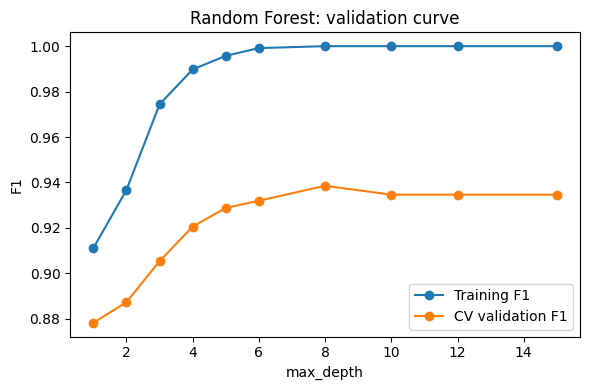

In [ ]:
from sklearn.model_selection import validation_curve

depth_range = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15]
rf_tmp = RandomForestClassifier(random_state=RANDOM_STATE,
            **{k: v for k, v in rf_search.best_params_.items() if k != 'max_depth'})
tr, va = validation_curve(rf_tmp, X_train, y_train, param_name='max_depth',
                          param_range=depth_range, cv=cv, scoring='f1', n_jobs=-1)
for d, t, v in zip(depth_range, tr.mean(1), va.mean(1)):
    print(f'max_depth={d:2d}  train F1={t:.3f}  validation F1={v:.3f}  gap={t-v:.3f}')

plt.figure(figsize=(6, 4))
plt.plot(depth_range, tr.mean(1), 'o-', label='Training F1')
plt.plot(depth_range, va.mean(1), 'o-', label='CV validation F1')
plt.xlabel('max_depth'); plt.ylabel('F1'); plt.title('Random Forest: validation curve')
plt.legend(); plt.tight_layout(); plt.savefig('fig_rf_validation_curve.png', dpi=150); plt.show()

The validation curve shows that very shallow trees (max_depth 1–2) underfit, as both training and validation F1 are low. As depth increases, validation F1 rises and reaches its highest value at max_depth = 8 (0.939), then stays flat at about 0.935. The training F1 reaches 1.000 from depth 8 onwards, so the model fits the training data almost perfectly. However, reducing the depth does not close the gap between training and validation F1, which stays around 0.06–0.07 for all depths from 3 upwards, while it lowers the validation F1. Therefore, max_depth = 8 gives the best balance, and the remaining gap is a known behaviour of Random Forest on a small dataset rather than something that can be fixed by tuning this hyperparameter.

In [ ]:
lr_best = lr_search.best_estimator_
rf_best = rf_search.best_estimator_

rows = []
for name, m in [('Logistic Regression (tuned)', lr_best), ('Random Forest (tuned)', rf_best)]:
    for set_name, Xs, ys in [('Train', X_train, y_train), ('Validation', X_val, y_val)]:
        rows.append({'Model': name, 'Set': set_name, **scores(m, Xs, ys)})
tuned = pd.DataFrame(rows).round(3)
tuned

,Model,Set,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression (tuned),Train,0.982,0.980,0.973,0.976,0.997
1,Logistic Regression (tuned),Validation,0.965,0.914,1.000,0.955,0.997
2,Random Forest (tuned),Train,1.000,1.000,1.000,1.000,1.000
3,Random Forest (tuned),Validation,0.977,1.000,0.938,0.968,0.998


On the validation set, which was not used during tuning, the tuned Logistic Regression detected all 32 malignant cases (recall 1.000) at the cost of 3 false alarms (precision 0.914), with an F1 of 0.955. Its training and validation scores are close, which confirms that it does not overfit. The tuned Random Forest achieved a higher validation F1 (0.968) with no false alarms (precision 1.000), but it missed 2 malignant cases (recall 0.938), and its perfect training scores show that it still fits the training data very closely. Because the validation set is small (86 samples), one prediction changes the scores noticeably, so we also rely on the cross-validation results, where Logistic Regression was higher and more stable (0.965 ± 0.016 vs. 0.939 ± 0.053). In a medical context, missing a malignant tumor is more serious than a false alarm, so the higher recall of Logistic Regression is an important advantage. The final comparison is made on the test set in Stage 5.

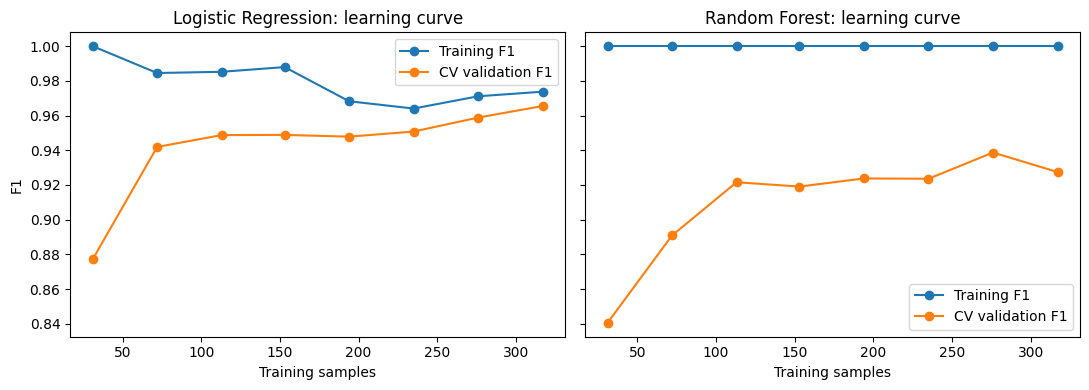

In [ ]:
from sklearn.model_selection import learning_curve

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (name, m) in zip(axes, [('Logistic Regression', lr_best), ('Random Forest', rf_best)]):
    sizes, tr, va = learning_curve(m, X_train, y_train, cv=cv, scoring='f1',
                                   train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=-1)
    ax.plot(sizes, tr.mean(1), 'o-', label='Training F1')
    ax.plot(sizes, va.mean(1), 'o-', label='CV validation F1')
    ax.set_title(f'{name}: learning curve'); ax.set_xlabel('Training samples'); ax.legend()
axes[0].set_ylabel('F1')
plt.tight_layout(); plt.savefig('fig_learning_curves.png', dpi=150); plt.show()

The learning curves show how performance changes as the training set grows. For Logistic Regression, the training and validation curves converge to about 0.97, with a small gap of about 0.01, which indicates a good fit with low bias and low variance; adding more data would bring only a small improvement. For Random Forest, the training F1 stays at 1.000 for all training sizes, while the validation F1 rises to about 0.93–0.94, leaving a gap of about 0.07. This shows that Random Forest has higher variance (it partly memorizes the training data) and would benefit from more data. Overall, Logistic Regression is the more suitable and more stable traditional model for this dataset.

In [ ]:
joblib.dump(lr_best, 'logreg_tuned.joblib')
joblib.dump(rf_best, 'rf_tuned.joblib')
print('Saved logreg_tuned.joblib and rf_tuned.joblib')

Saved logreg_tuned.joblib and rf_tuned.joblib


The tuned models were saved so they can be evaluated on the test set in Stage 5.

#Stage 5: Evaluation on Test Set


#Discussion

#Conclusion